In [1]:
import folium, datetime
import numpy as np
import pandas as pd
import geopandas as gpd
import pyarrow.parquet as pq
from glob import glob
from os.path import join
from multiprocessing import Pool
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.measures import individual
from skmob.preprocessing import filtering, compression, detection, clustering
import branca.colormap as cm
import matplotlib.pyplot as plt

In [2]:
data_path = ""
df = pd.read_parquet(data_path, engine='pyarrow')
date = df.index.get_level_values(0)[0]
df

uncorrelated_entropy  \
date                  zipcode metric                         
2024-03-15_2024-04-30 00012   mean                5.605072   
                              median              5.975481   
                              sum                28.025358   
                      00016   mean                0.000000   
                              median              0.000000   
...                                                    ...   
                      96161   median              3.144976   
                              sum            114337.343746   
                      96162   mean                4.218456   
                              median              4.297079   
                              sum                97.024485   

                                      radius_of_gyration  \
date                  zipcode metric                       
2024-03-15_2024-04-30 00012   mean             29.800638   
                              median            9.992919   
                              sum             149.003188   
                      00016   mean              0.000000   
                              median            0.000000   
...                                                  ...   
                      96161   median            0.271736   
                              sum          933129.604869   
                      96162   mean             40.429258   
                              median            4.446159   
                              sum             929.872935   

                                      distance_straight_line  
date                  zipcode metric                          
2024-03-15_2024-04-30 00012   mean              5.181733e+02  
                              median            4.224599e+01  
                              sum               2.590867e+03  
                      00016   mean              0.000000e+00  
                              median            0.000000e+00  
...                                                      ...  
                      96161   median            1.421821e+00  
                              sum               1.976324e+07  
                      96162   mean              4.684397e+02  
                              median            2.035539e+01  
                              sum               1.077411e+04  

[5157 rows x 3 columns]

In [3]:
path_zips = "/glade/work/cbecker/california_zip.geojson"
gdf_zips = gpd.read_file(path_zips)
gdf_zips

,OBJECTID,ZIP_CODE,PO_NAME,STATE,POPULATION,POP_SQMI,SQMI,geometry
0,1,00012,Mt Meadows Area,CA,-99,-99.00,30.92,"POLYGON ((-120.84352 40.24962, -120.84360 40.2..."
1,2,00016,Sequoia National Forest,CA,-99,-99.00,39.33,"POLYGON ((-118.44021 35.55794, -118.38035 35.5..."
2,3,00017,Northeast Fresno County,CA,-99,-99.00,564.38,"POLYGON ((-118.77501 37.46305, -118.77447 37.4..."
3,4,00018,Los Padres Ntl Forest,CA,-99,-99.00,90.83,"POLYGON ((-118.81778 34.56244, -118.81779 34.5..."
4,5,00019,Lassen Ntl Forest,CA,-99,-99.00,412.59,"POLYGON ((-119.99861 40.77159, -119.99848 40.7..."
...,...,...,...,...,...,...,...,...
1716,1717,96146,Olympic Valley,CA,1152,149.42,7.71,"POLYGON ((-120.20156 39.21418, -120.19868 39.2..."
1717,1718,96148,Tahoe Vista,CA,1487,991.33,1.50,"POLYGON ((-120.03947 39.23825, -120.04087 39.2..."
1718,1719,96150,South Lake Tahoe,CA,32999,151.87,217.28,"POLYGON ((-119.94957 38.96422, -119.94310 38.9..."
1719,1720,96161,Truckee,CA,19416,99.57,194.99,"POLYGON ((-120.09864 39.44512, -120.09833 39.4..."


In [4]:
gdf_zips_metrics = pd.merge(gdf_zips, df.xs("mean", level="metric"), left_on="ZIP_CODE", right_on="zipcode")
gdf_zips_metrics

,OBJECTID,ZIP_CODE,PO_NAME,STATE,POPULATION,POP_SQMI,SQMI,geometry,uncorrelated_entropy,radius_of_gyration,distance_straight_line
0,1,00012,Mt Meadows Area,CA,-99,-99.00,30.92,"POLYGON ((-120.84352 40.24962, -120.84360 40.2...",5.605072,29.800638,518.173301
1,2,00016,Sequoia National Forest,CA,-99,-99.00,39.33,"POLYGON ((-118.44021 35.55794, -118.38035 35.5...",0.000000,0.000000,0.000000
2,3,00017,Northeast Fresno County,CA,-99,-99.00,564.38,"POLYGON ((-118.77501 37.46305, -118.77447 37.4...",4.362076,66.967532,1343.001525
3,4,00018,Los Padres Ntl Forest,CA,-99,-99.00,90.83,"POLYGON ((-118.81778 34.56244, -118.81779 34.5...",3.954670,20.891891,620.023955
4,5,00019,Lassen Ntl Forest,CA,-99,-99.00,412.59,"POLYGON ((-119.99861 40.77159, -119.99848 40.7...",3.645509,37.572985,356.822846
...,...,...,...,...,...,...,...,...,...,...,...
1714,1717,96146,Olympic Valley,CA,1152,149.42,7.71,"POLYGON ((-120.20156 39.21418, -120.19868 39.2...",4.884587,39.037313,1041.035026
1715,1718,96148,Tahoe Vista,CA,1487,991.33,1.50,"POLYGON ((-120.03947 39.23825, -120.04087 39.2...",4.754121,48.088921,1088.116781
1716,1719,96150,South Lake Tahoe,CA,32999,151.87,217.28,"POLYGON ((-119.94957 38.96422, -119.94310 38.9...",2.947020,25.692468,474.558626
1717,1720,96161,Truckee,CA,19416,99.57,194.99,"POLYGON ((-120.09864 39.44512, -120.09833 39.4...",3.457329,28.215948,597.600292


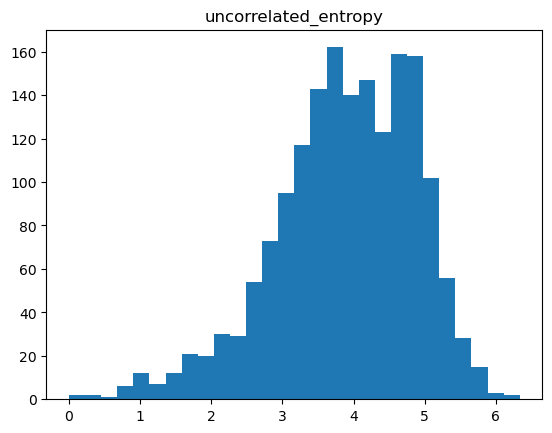

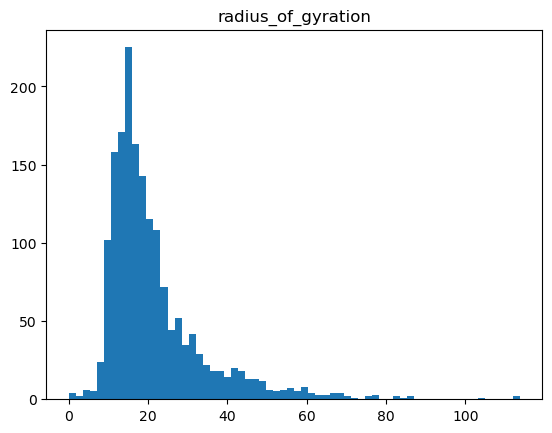

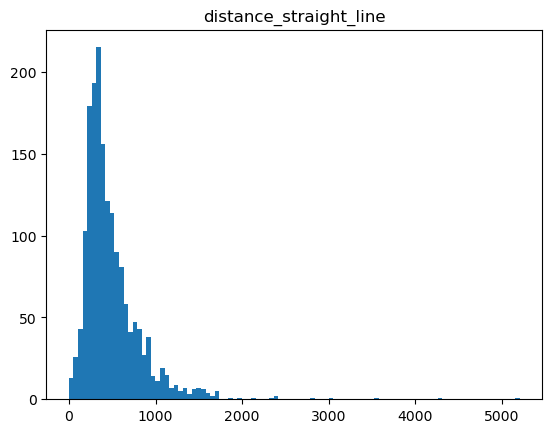

In [5]:
for col in df.columns:
    hist, bins, _ = plt.hist(np.sort(gdf_zips_metrics[col]), bins='fd')
    plt.title(f"{col}")
    plt.show()

In [6]:
gdf_zips_metrics

,OBJECTID,ZIP_CODE,PO_NAME,STATE,POPULATION,POP_SQMI,SQMI,geometry,uncorrelated_entropy,radius_of_gyration,distance_straight_line
0,1,00012,Mt Meadows Area,CA,-99,-99.00,30.92,"POLYGON ((-120.84352 40.24962, -120.84360 40.2...",5.605072,29.800638,518.173301
1,2,00016,Sequoia National Forest,CA,-99,-99.00,39.33,"POLYGON ((-118.44021 35.55794, -118.38035 35.5...",0.000000,0.000000,0.000000
2,3,00017,Northeast Fresno County,CA,-99,-99.00,564.38,"POLYGON ((-118.77501 37.46305, -118.77447 37.4...",4.362076,66.967532,1343.001525
3,4,00018,Los Padres Ntl Forest,CA,-99,-99.00,90.83,"POLYGON ((-118.81778 34.56244, -118.81779 34.5...",3.954670,20.891891,620.023955
4,5,00019,Lassen Ntl Forest,CA,-99,-99.00,412.59,"POLYGON ((-119.99861 40.77159, -119.99848 40.7...",3.645509,37.572985,356.822846
...,...,...,...,...,...,...,...,...,...,...,...
1714,1717,96146,Olympic Valley,CA,1152,149.42,7.71,"POLYGON ((-120.20156 39.21418, -120.19868 39.2...",4.884587,39.037313,1041.035026
1715,1718,96148,Tahoe Vista,CA,1487,991.33,1.50,"POLYGON ((-120.03947 39.23825, -120.04087 39.2...",4.754121,48.088921,1088.116781
1716,1719,96150,South Lake Tahoe,CA,32999,151.87,217.28,"POLYGON ((-119.94957 38.96422, -119.94310 38.9...",2.947020,25.692468,474.558626
1717,1720,96161,Truckee,CA,19416,99.57,194.99,"POLYGON ((-120.09864 39.44512, -120.09833 39.4...",3.457329,28.215948,597.600292


In [ ]:
col_idx = 0
col = df.columns[col_idx]
vmax = df.xs("mean", level="metric")[col].max()
linear = cm.linear.GnBu_03.to_step(n=8, data=gdf_zips_metrics[col], method="linear")
tooltips = ["ZIP_CODE", "PO_NAME", "POPULATION", "POP_SQMI", f"{col}"]

m = folium.Map(location=[34.0549, -118.2426],
               zoom_start=8)

folium.GeoJson(
    gdf_zips_metrics,
    style_function=lambda feature: {
        "fillColor": linear(feature["properties"][f"{col}"]),
        "fillOpacity": 0.9,
        "color": "black",
        "weight": 0.5,
    },
    tooltip=folium.features.GeoJsonTooltip(tooltips),
).add_to(m)

title_html = f'''
     <h3 align="center" style="font-size:20px"><b>{date}_{col}</b></h3>
     '''
m.get_root().html.add_child(folium.Element(title_html))

m.save(f"./html/{date}_{col}.html")
m

![title](img/uncorrentropy_byzip.png)

In [ ]:
col_idx = 1
col = df.columns[col_idx]
vmax = df.xs("mean", level="metric")[col].max()
linear = cm.linear.GnBu_03.to_step(n=8, data=gdf_zips_metrics[col], method="linear")
tooltips = ["ZIP_CODE", "PO_NAME", "POPULATION", "POP_SQMI", f"{col}"]

m = folium.Map(location=[34.0549, -118.2426],
               zoom_start=8)

folium.GeoJson(
    gdf_zips_metrics,
    style_function=lambda feature: {
        "fillColor": linear(feature["properties"][f"{col}"]),
        "fillOpacity": 0.9,
        "color": "black",
        "weight": 0.5,
    },
    tooltip=folium.features.GeoJsonTooltip(tooltips),
).add_to(m)

title_html = f'''
     <h3 align="center" style="font-size:20px"><b>{date}_{col}</b></h3>
     '''
m.get_root().html.add_child(folium.Element(title_html))

m.save(f"./html/{date}_{col}.html")
m

![title](img/radgyr_byzip.png)

In [ ]:
col_idx = 2
col = df.columns[col_idx]
vmax = df.xs("mean", level="metric")[col].max()
linear = cm.linear.GnBu_03.to_step(n=8, data=gdf_zips_metrics[col], method="linear")
tooltips = ["ZIP_CODE", "PO_NAME", "POPULATION", "POP_SQMI", f"{col}"]

m = folium.Map(location=[34.0549, -118.2426],
               zoom_start=8)

folium.GeoJson(
    gdf_zips_metrics,
    style_function=lambda feature: {
        "fillColor": linear(feature["properties"][f"{col}"]),
        "fillOpacity": 0.9,
        "color": "black",
        "weight": 0.5,
    },
    tooltip=folium.features.GeoJsonTooltip(tooltips),
).add_to(m)

title_html = f'''
     <h3 align="center" style="font-size:20px"><b>{date}_{col}</b></h3>
     '''
m.get_root().html.add_child(folium.Element(title_html))

m.save(f"./html/{date}_{col}.html")
m

![title](img/diststline_byzip.png)